# NASA Wildfire Intelligence

## Team members + GitHub link
- Bertrand MAIGRE (team head)
- Victor MICHELON (team member)
- Jean Baptiste PASTEAU (team member)
- Oscar DUJARDIN (team member)

GitHub : https://github.com/BertrandM78/nasa-wildfire-intelligence

## 0. Description du dataset

Ce dataset recense les **feux actifs repérés par satellite aux États-Unis**, de septembre 2010 à septembre 2020.

**Que représente une ligne ?** Une *détection*. Deux satellites de la NASA, **Terra** et **Aqua**, portent un capteur appelé **MODIS**.
Plusieurs fois par jour, ils survolent le pays et repèrent les zones d'environ 1 km × 1 km nettement plus chaudes que leur entourage.
Chaque zone repérée devient une ligne du tableau. C'est le plus souvent un feu de végétation, mais ce peut être aussi un volcan, une usine ou une plateforme en mer.

**Qui produit les données ?** Le service **NASA FIRMS** (*Fire Information for Resource Management System*).

**Zone couverte :** les 48 États continentaux, l'Alaska et Hawaï.

**Deux fichiers :**
- **archive** (sept. 2010 → juin 2020, 1,18 M lignes) : la version définitive, vérifiée par l'Université du Maryland ;
- **NRT** pour *Near Real-Time* (juillet → sept. 2020, 66 k lignes) : la version publiée quelques heures après le passage du satellite. Elle est remplacée par la version définitive 2 à 3 mois plus tard. Elle n'a pas de colonne `type`.

**Les trois dimensions demandées :**
- **quand** (temporelle) : `acq_date`, `acq_time` ;
- **où** (spatiale) : `latitude`, `longitude` ;
- **quoi** (analytique) : intensité (`frp`, `brightness`), fiabilité (`confidence`), satellite, jour/nuit, type de source.

**Sens de chaque colonne :**

| Colonne | Signification |
|---|---|
| latitude, longitude | centre du pixel détecté (WGS84) |
| brightness | température de brillance canal 21/22 (K) |
| scan, track | taille réelle du pixel (km) |
| acq_date, acq_time | date et heure UTC (HHMM) de l'acquisition |
| satellite | Terra ou Aqua |
| confidence | confiance de détection (0–100 %) |
| version | version de collection (6.03 archive, 6.0NRT temps réel) |
| bright_t31 | température de brillance canal 31 (K) |
| frp | Fire Radiative Power (MW) — intensité du feu |
| daynight | D = jour, N = nuit |
| type | 0 végétation, 1 volcan, 2 source statique terrestre, 3 offshore (archive seulement) |

## Import libraries

In [ ]:
# Toutes les bibliothèques utilisées par le projet
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import socket
import warnings
from dash import Dash, Input, Output, dcc, html
from mlxtend.frequent_patterns import association_rules, fpgrowth
from pathlib import Path
from sklearn.cluster import DBSCAN
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.max_columns", None)

## Function definitions
Toutes les fonctions du projet, regroupées par étape. Chacune est précédée d'un commentaire **Function / Input / Output**.

*Ces cellules sont générées automatiquement depuis `src/wildfire/` par `scripts/build_notebook.py` : pour modifier une fonction, modifier le fichier .py puis relancer le script.*

In [ ]:
# ===== Configuration : chemins des fichiers, équipe, dataset (src/wildfire/config.py) =====

# Classe utilisée comme espace de noms : config.ARCHIVE_FILE, config.TEAM, etc.
class config:
    # Racine du projet (…/nasa-wildfire-intelligence)
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # racine du projet

    DATA_RAW = ROOT / "data" / "raw"
    DATA_EXTERNAL = ROOT / "data" / "external"
    DATA_PROCESSED = ROOT / "data" / "processed"
    FIGURES = ROOT / "reports" / "figures"

    ARCHIVE_FILE = DATA_RAW / "fire_archive_M6_156000.csv.gz"
    NRT_FILE = DATA_RAW / "fire_nrt_M6_156000.csv.gz"

    # Dataset externe : limites des États (US Census Bureau, 2018, 1:20M)
    # Source : https://www2.census.gov/geo/tiger/GENZ2018/shp/cb_2018_us_state_20m.zip
    STATES_FILE = DATA_EXTERNAL / "cb_2018_us_state_20m.zip"

    # Données nettoyées et enrichies (cache régénéré par le notebook)
    CLEAN_FILE = DATA_PROCESSED / "fires_clean.parquet"

    DATASET_NAME = "NASA FIRMS — MODIS Collection 6 Active Fires (USA, 2010-2020)"
    EXTERNAL_DATASET_NAME = "US Census Bureau — limites des États 2018 (cb_2018_us_state_20m)"

    TEAM = [
        "Bertrand MAIGRE (chef d'équipe)",
        "Victor MICHELON",
        "Jean Baptiste PASTEAU",
        "Oscar DUJARDIN",
    ]
    GITHUB_URL = "https://github.com/BertrandM78/nasa-wildfire-intelligence"

    # Livrables (nommés d'après le chef d'équipe, comme exigé par les consignes)
    REPORTS = ROOT / "reports"
    DASHBOARD_HTML = REPORTS / "Maigre_dashboard.html"
    DASHBOARD_PDF = REPORTS / "Maigre_dashboard.pdf"

In [ ]:
# ===== Étape 1 — Chargement des données (src/wildfire/loading.py) =====

# Function: load_data
# Lit un fichier CSV FIRMS (compressé ou non) dans un DataFrame.
# Input:  file_path (str | Path) — chemin vers le CSV (.csv ou .csv.gz)
# Output: DataFrame pandas, une ligne par détection de point chaud
def load_data(file_path):
    # acq_time est au format HHMM (ex. "0457") : lu en texte pour garder les zéros initiaux
    # version vaut 6.03 (archive) ou "6.0NRT" (NRT) : lue en texte pour un type homogène après fusion
    return pd.read_csv(file_path, dtype={"acq_time": str, "version": str})


# Function: merge_archive_nrt
# Concatène l'archive (qualité standard) et le fichier NRT (temps quasi réel).
# Input:  archive (DataFrame), nrt (DataFrame)
# Output: DataFrame unique avec une colonne `source` ("archive" / "nrt")
def merge_archive_nrt(archive, nrt):
    archive = archive.assign(source="archive")  # trace de l'origine de chaque ligne
    nrt = nrt.assign(source="nrt")
    # Le NRT n'a pas de colonne `type` : elle sera NaN pour ces lignes (traité en phase 2)
    return pd.concat([archive, nrt], ignore_index=True)


# Function: save_processed
# Sauvegarde les données nettoyées au format parquet (lecture ~10x plus rapide que le CSV).
# Input:  df (DataFrame), file_path (str | Path)
# Output: aucun (écrit le fichier)
def save_processed(df, file_path):
    df.to_parquet(file_path, index=False)


# Function: load_processed
# Recharge les données nettoyées depuis le cache parquet.
# Input:  file_path (str | Path)
# Output: DataFrame
def load_processed(file_path):
    return pd.read_parquet(file_path)

In [ ]:
# ===== Étape 1 — Exploration (src/wildfire/exploration.py) =====

# Function: dataset_shape
# Donne le nombre de lignes et de colonnes.
# Input:  df (DataFrame)
# Output: dict {"rows": int, "columns": int}
def dataset_shape(df):
    return {"rows": df.shape[0], "columns": df.shape[1]}


# Function: column_types
# Liste le type pandas de chaque colonne.
# Input:  df (DataFrame)
# Output: DataFrame (colonne, dtype)
def column_types(df):
    return df.dtypes.astype(str).rename("dtype").to_frame()


# Function: missing_values
# Compte les valeurs manquantes par colonne (absolu et en %).
# Input:  df (DataFrame)
# Output: DataFrame (colonne, n_missing, pct_missing)
def missing_values(df):
    n = df.isna().sum()
    return pd.DataFrame({"n_missing": n, "pct_missing": (n / len(df) * 100).round(2)})


# Function: value_ranges
# Plage de valeurs de chaque variable : min/max pour les numériques,
# modalités distinctes pour les catégorielles.
# Input:  df (DataFrame)
# Output: DataFrame (colonne, min, max, n_unique)
def value_ranges(df):
    rows = {}
    for col in df.columns:
        s = df[col].dropna()
        rows[col] = {
            "min": s.min() if len(s) else None,  # min/max fonctionnent aussi sur dates/texte (ordre lexical)
            "max": s.max() if len(s) else None,
            "n_unique": s.nunique(),
        }
    return pd.DataFrame(rows).T


# ---------------------------------------------------------------------------
# Graphiques d'exploration
# ---------------------------------------------------------------------------
# Function: plot_frp_distribution
# Histogramme de la Fire Radiative Power (intensité du feu, en MW).
# Échelle log sur l'axe x car la distribution est très asymétrique
# (médiane ~23 MW, mais quelques feux dépassent 10 000 MW).
# Input:  df (DataFrame) avec une colonne `frp`
# Output: figure matplotlib
def plot_frp_distribution(df):
    frp = df.loc[df["frp"] > 0, "frp"]  # log impossible pour frp <= 0 (cas traités en phase 2)
    bins = np.logspace(np.log10(frp.min()), np.log10(frp.max()), 60)  # classes régulières en échelle log
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(frp, bins=bins, color="#d95f02")
    ax.set_xscale("log")
    ax.axvline(frp.median(), color="black", ls="--", label=f"médiane = {frp.median():.0f} MW")
    ax.set(xlabel="FRP (MW, échelle log)", ylabel="Nombre de détections",
           title="Distribution de l'intensité des feux (FRP)")
    ax.legend()
    fig.tight_layout()
    return fig


# Function: plot_monthly_detections
# Nombre de détections par mois, en distinguant archive et NRT,
# pour visualiser la saisonnalité et la couverture temporelle.
# Input:  df (DataFrame) avec les colonnes `acq_date` et `source`
# Output: figure matplotlib
def plot_monthly_detections(df):
    month = pd.to_datetime(df["acq_date"]).dt.to_period("M").dt.to_timestamp()  # 1er jour du mois
    counts = df.groupby([month.rename("month"), "source"]).size().unstack("source")
    fig, ax = plt.subplots(figsize=(11, 4))
    for source, color in [("archive", "#1b9e77"), ("nrt", "#d95f02")]:
        if source in counts:
            ax.plot(counts.index, counts[source], color=color, label=source)
    ax.set(xlabel="Mois", ylabel="Nombre de détections",
           title="Détections de points chauds par mois (2010-09 → 2020-09)")
    ax.legend(title="Fichier")
    fig.tight_layout()
    return fig


# Function: plot_spatial_distribution
# Carte des détections (longitude / latitude), colorées par `type`.
# Les 1,25 M points sont tracés en très petit et semi-transparents.
# Input:  df (DataFrame) avec `latitude`, `longitude`, `type`
#         sample (int | None) — nombre de points tirés au hasard (None = tous)
# Output: figure matplotlib
def plot_spatial_distribution(df, sample=None):
    if sample is not None and sample < len(df):
        df = df.sample(sample, random_state=42)  # graine fixe : figure reproductible
    # Ordre de tracé : du plus fréquent au plus rare, pour que les types rares
    # (volcans, sources statiques, offshore) ne soient pas masqués par la végétation.
    # (type, libellé, couleur, taille du point)
    layers = [
        (0, "0 végétation", "#1b9e77", 0.2),
        (None, "NRT (type inconnu)", "grey", 0.2),  # None = lignes NRT sans colonne type
        (2, "2 source statique", "#7570b3", 1.0),
        (1, "1 volcan", "#e7298a", 3.0),
        (3, "3 offshore", "#1f78b4", 3.0),
    ]
    fig, ax = plt.subplots(figsize=(11, 6))
    for t, label, color, size in layers:
        sub = df[df["type"].isna()] if t is None else df[df["type"] == t]
        ax.scatter(sub["longitude"], sub["latitude"], s=size, alpha=0.4, color=color,
                   label=f"{label} ({len(sub):,})".replace(",", " "),
                   rasterized=True)  # rasterized : fichier léger malgré le nombre de points
    ax.set(xlabel="Longitude", ylabel="Latitude", title="Localisation des détections par type")
    ax.legend(markerscale=6, loc="upper right")  # coin vide (océan), ne masque ni Hawaï ni l'Alaska
    fig.tight_layout()
    return fig

In [ ]:
# ===== Étape 2 — Nettoyage (src/wildfire/cleaning.py) =====

# Seuil de confiance par défaut : FIRMS classe les détections MODIS en
# "faible" (< 30 %), "nominale" (30–79 %) et "haute" (>= 80 %).
MIN_CONFIDENCE = 30

# Colonnes retirées et pourquoi (voir drop_useless_columns)
USELESS_COLUMNS = {
    "instrument": "toujours 'MODIS' : n'apporte aucune information",
    "version": "redondant avec `source` (6.03 = archive, 6.0NRT = nrt)",
    "type": "toujours 0 après le filtre végétation",
    "acq_time": "fusionné avec acq_date dans `acq_datetime`",
}


# Function: infer_nrt_type
# Le fichier NRT n'a pas de colonne `type`. On la reconstitue à partir de l'archive :
# si une détection NRT tombe dans une case de ~1 km où l'archive a déjà vu un volcan,
# une source statique ou une plateforme offshore, elle reçoit ce type ; sinon type 0.
# Input:  df (DataFrame fusionné archive + nrt, colonnes `latitude`, `longitude`, `type`, `source`)
#         decimals (int) — arrondi des coordonnées définissant la case (2 décimales ≈ 1 km)
# Output: DataFrame avec `type` rempli pour les lignes NRT
def infer_nrt_type(df, decimals=2):
    df = df.copy()
    cell = df["latitude"].round(decimals).astype(str) + "_" + df["longitude"].round(decimals).astype(str)
    # Type non-végétation le plus fréquent observé dans chaque case de l'archive
    known = df["source"].eq("archive") & df["type"].ne(0)
    cell_type = df.loc[known, "type"].groupby(cell[known]).agg(lambda s: s.mode().iloc[0])
    is_nrt = df["source"].eq("nrt")
    # Case connue -> type de l'archive ; case inconnue -> 0 (végétation)
    df.loc[is_nrt, "type"] = cell[is_nrt].map(cell_type).fillna(0)
    df["type"] = df["type"].astype(int)
    return df


# Function: filter_vegetation
# Ne garde que les feux de végétation (type 0), sujet du projet.
# Input:  df (DataFrame avec `type` complet)
# Output: DataFrame filtré
def filter_vegetation(df):
    return df[df["type"] == 0]


# Function: remove_invalid_frp
# Retire les détections dont l'intensité (FRP) vaut 0 ou est négative :
# une puissance négative est impossible, et 0 signifie que la FRP n'a pas été calculée.
# Input:  df (DataFrame)
# Output: DataFrame avec frp > 0
def remove_invalid_frp(df):
    return df[df["frp"] > 0]


# Function: filter_confidence
# Retire les détections de faible confiance (fausses alertes probables).
# Input:  df (DataFrame), min_confidence (int, %) — seuil minimum conservé
# Output: DataFrame avec confidence >= min_confidence
def filter_confidence(df, min_confidence=MIN_CONFIDENCE):
    return df[df["confidence"] >= min_confidence]


# Function: add_time_features
# Crée une vraie date-heure UTC et des colonnes temporelles utiles aux requêtes.
# Input:  df (DataFrame avec `acq_date` "AAAA-MM-JJ" et `acq_time` "HHMM")
# Output: DataFrame avec acq_datetime, year, month, season
def add_time_features(df):
    df = df.copy()
    df["acq_datetime"] = pd.to_datetime(df["acq_date"] + " " + df["acq_time"],
                                        format="%Y-%m-%d %H%M", utc=True)
    df["acq_date"] = df["acq_datetime"].dt.normalize().dt.tz_localize(None)  # date seule, type datetime
    df["year"] = df["acq_datetime"].dt.year
    df["month"] = df["acq_datetime"].dt.month
    # Saisons météorologiques de l'hémisphère Nord (déc-jan-fév = hiver, etc.)
    seasons = {12: "hiver", 1: "hiver", 2: "hiver", 3: "printemps", 4: "printemps", 5: "printemps",
               6: "été", 7: "été", 8: "été", 9: "automne", 10: "automne", 11: "automne"}
    df["season"] = df["month"].map(seasons)
    return df


# Function: drop_useless_columns
# Supprime les colonnes qui n'apportent plus d'information (raisons dans USELESS_COLUMNS).
# Input:  df (DataFrame)
# Output: DataFrame sans ces colonnes
def drop_useless_columns(df):
    return df.drop(columns=[c for c in USELESS_COLUMNS if c in df.columns])


# Function: clean_data
# Enchaîne toutes les étapes de nettoyage et note le nombre de lignes après chacune.
# Input:  df (DataFrame brut fusionné), min_confidence (int, %)
# Output: (DataFrame nettoyé, DataFrame-journal des étapes : lignes restantes / retirées)
def clean_data(df, min_confidence=MIN_CONFIDENCE):
    log = [("Données brutes (archive + NRT)", len(df))]
    df = infer_nrt_type(df)
    df = filter_vegetation(df);                     log.append(("Feux de végétation uniquement (type 0)", len(df)))
    df = remove_invalid_frp(df);                    log.append(("FRP > 0", len(df)))
    df = filter_confidence(df, min_confidence);     log.append((f"Confiance >= {min_confidence} %", len(df)))
    df = add_time_features(df)
    df = drop_useless_columns(df).reset_index(drop=True)
    log = pd.DataFrame(log, columns=["étape", "lignes restantes"])
    log["lignes retirées"] = (-log["lignes restantes"].diff()).fillna(0).astype(int)
    return df, log

In [ ]:
# ===== Étape 2 — Enrichissement géographique (dataset externe) (src/wildfire/geo.py) =====

# Régions officielles du US Census Bureau (Alaska et Hawaï font partie de "West")
CENSUS_REGIONS = {
    "Northeast": ["CT", "ME", "MA", "NH", "RI", "VT", "NJ", "NY", "PA"],
    "Midwest": ["IL", "IN", "MI", "OH", "WI", "IA", "KS", "MN", "MO", "NE", "ND", "SD"],
    "South": ["DE", "DC", "FL", "GA", "MD", "NC", "SC", "VA", "WV", "AL", "KY", "MS", "TN",
              "AR", "LA", "OK", "TX"],
    "West": ["AZ", "CO", "ID", "MT", "NV", "NM", "UT", "WY", "AK", "CA", "HI", "OR", "WA"],
}


# Function: load_states
# Charge les polygones des États américains.
# Input:  file_path (str | Path) — shapefile zippé du Census
# Output: GeoDataFrame (state = code à 2 lettres, state_name, geometry) en WGS84
def load_states(file_path):
    states = gpd.read_file(file_path)[["STUSPS", "NAME", "geometry"]]
    states = states.rename(columns={"STUSPS": "state", "NAME": "state_name"})
    return states.to_crs("EPSG:4326")  # même système de coordonnées que les données FIRMS


# Function: add_state
# Associe chaque détection à l'État qui la contient (jointure spatiale).
# Les contours du Census sont simplifiés : quelques points côtiers tombent juste
# à l'extérieur. Ils sont rattachés à l'État le plus proche s'il est à moins de max_km.
# Input:  df (DataFrame avec latitude/longitude), states (GeoDataFrame de load_states),
#         max_km (float) — distance maximale pour le rattachement des points côtiers
# Output: DataFrame avec les colonnes `state` et `state_name` (NaN si hors des États)
def add_state(df, states, max_km=10):
    points = gpd.GeoDataFrame(df[[]], geometry=gpd.points_from_xy(df["longitude"], df["latitude"]),
                              crs="EPSG:4326")
    # 1) point à l'intérieur d'un État
    joined = gpd.sjoin(points, states, how="left", predicate="within")
    joined = joined[~joined.index.duplicated()]  # sécurité si un point touche deux polygones
    # 2) points non trouvés : État le plus proche, en projection métrique (Albers USA, EPSG:5070)
    missing = joined["state"].isna()
    if missing.any():
        near = gpd.sjoin_nearest(points[missing].to_crs("EPSG:5070"), states.to_crs("EPSG:5070"),
                                 how="left", max_distance=max_km * 1000)
        near = near[~near.index.duplicated()]
        joined.loc[missing, ["state", "state_name"]] = near[["state", "state_name"]]
    df = df.copy()
    df["state"] = joined["state"]
    df["state_name"] = joined["state_name"]
    return df


# Function: add_region
# Ajoute la grande région du Census (Northeast, Midwest, South, West) à partir de l'État.
# Input:  df (DataFrame avec `state`)
# Output: DataFrame avec la colonne `region`
def add_region(df):
    state_to_region = {s: r for r, codes in CENSUS_REGIONS.items() for s in codes}
    df = df.copy()
    df["region"] = df["state"].map(state_to_region)
    return df

In [ ]:
# ===== Q1 — Agrégation (src/wildfire/q1_aggregation.py) =====

# Function: aggregate_by_state
# Calcule, pour chaque État, trois indicateurs d'activité des feux :
#   - n_detections : nombre de détections (≈ surface touchée × durée)
#   - total_frp_gw : somme des FRP en gigawatts (≈ énergie totale dégagée)
#   - median_frp   : FRP médiane en MW (intensité d'un feu "typique")
#   - share_pct    : part de l'énergie nationale (%)
# Input:  df (DataFrame nettoyé avec `state`, `state_name`, `frp`)
# Output: DataFrame, une ligne par État, trié par énergie décroissante
def aggregate_by_state(df):
    agg = (df.groupby(["state", "state_name"])
             .agg(n_detections=("frp", "size"),     # nombre de lignes
                  total_frp=("frp", "sum"),         # somme des MW
                  median_frp=("frp", "median"))
             .reset_index())
    agg["total_frp_gw"] = (agg["total_frp"] / 1000).round(1)   # MW -> GW, plus lisible
    agg["share_pct"] = (agg["total_frp"] / agg["total_frp"].sum() * 100).round(1)
    agg["median_frp"] = agg["median_frp"].round(1)
    return agg.drop(columns="total_frp").sort_values("total_frp_gw", ascending=False).reset_index(drop=True)


# Function: aggregate_by_year_region
# Nombre de détections par année et par grande région.
# Input:  df (DataFrame nettoyé avec `year`, `region`)
# Output: DataFrame (year, region, n_detections)
def aggregate_by_year_region(df):
    return df.groupby(["year", "region"]).size().rename("n_detections").reset_index()


# Function: plot_state_map
# Carte des États colorés selon un indicateur.
# Input:  agg (DataFrame de aggregate_by_state), metric (str) — colonne à afficher
# Output: figure plotly
def plot_state_map(agg, metric="total_frp_gw"):
    titles = {"total_frp_gw": "Énergie cumulée des feux (GW)", "n_detections": "Nombre de détections",
              "median_frp": "FRP médiane (MW)"}
    fig = px.choropleth(agg, locations="state", locationmode="USA-states", scope="usa",
                        color=metric, color_continuous_scale="OrRd",
                        hover_name="state_name",
                        hover_data={"state": False, "n_detections": ":,", "total_frp_gw": ":,",
                                    "median_frp": True, "share_pct": True},
                        labels={metric: titles.get(metric, metric)})
    fig.update_layout(title=f"Q1 — {titles.get(metric, metric)} par État (2010-2020)",
                      margin=dict(l=0, r=0, t=50, b=0))
    return fig


# Function: plot_top_states
# Diagramme en barres des n États qui ont dégagé le plus d'énergie.
# Input:  agg (DataFrame de aggregate_by_state), n (int) — nombre d'États affichés
# Output: figure plotly
def plot_top_states(agg, n=10):
    top = agg.head(n).iloc[::-1]  # inversé : le 1er en haut du graphique
    fig = px.bar(top, x="total_frp_gw", y="state_name", orientation="h", text="share_pct",
                 labels={"total_frp_gw": "Énergie cumulée (GW)", "state_name": ""},
                 color_discrete_sequence=["#d95f02"])
    fig.update_traces(texttemplate="%{text} %", textposition="outside", cliponaxis=False)  # étiquette jamais coupée
    fig.update_layout(title=f"Q1 — Top {n} des États par énergie cumulée des feux")
    return fig


# Function: plot_year_region
# Barres empilées : nombre de détections par année, réparti par région.
# Input:  by_year (DataFrame de aggregate_by_year_region)
# Output: figure plotly
def plot_year_region(by_year):
    fig = px.bar(by_year, x="year", y="n_detections", color="region",
                 labels={"year": "Année", "n_detections": "Nombre de détections", "region": "Région"},
                 category_orders={"region": ["West", "South", "Midwest", "Northeast"]},
                 color_discrete_sequence=["#d95f02", "#1b9e77", "#7570b3", "#e7298a"])
    fig.update_layout(title="Q1 — Détections par année et par région "
                            "(2010 et 2020 incomplètes)")
    return fig

In [ ]:
# ===== Q2 — Motifs fréquents (src/wildfire/q2_patterns.py) =====

# Classes d'intensité (FRP en MW), proches des quantiles observés en §1.5 :
# ~20 % des détections < 10 MW, ~15 % > 100 MW.
FRP_BINS = [0, 10, 100, np.inf]
FRP_LABELS = ["faible", "moyenne", "forte"]


# Function: build_transactions
# Transforme chaque détection en "panier" d'attributs (une transaction) :
#   saison, région, moment (jour/nuit), intensité (classe de FRP).
# La confiance n'est pas utilisée : la NASA la calcule en partie à partir de la chaleur
# du pixel, elle produirait des règles évidentes ("feu fort -> confiance haute").
# Chaque attribut devient une colonne booléenne "nom=valeur" (encodage one-hot).
# Input:  df (DataFrame nettoyé)
# Output: DataFrame booléen (une ligne par détection, une colonne par item)
def build_transactions(df):
    items = pd.DataFrame({
        "saison": df["season"],
        "région": df["region"],
        "moment": df["daynight"].map({"D": "jour", "N": "nuit"}),
        "intensité": pd.cut(df["frp"], bins=FRP_BINS, labels=FRP_LABELS),
    })
    return pd.get_dummies(items.astype(str), prefix_sep="=").astype(bool)


# Function: remove_redundant_rules
# Retire les règles "redondantes" : une règle {A, X} -> B est supprimée s'il existe une
# règle plus courte {A} -> B presque aussi forte. Ajouter X n'apporte alors rien.
# Input:  rules (DataFrame mlxtend, antecedents/consequents en frozenset)
#         min_gain (float) — gain de lift minimal exigé pour garder la règle longue (0.05 = +5 %)
# Output: DataFrame des règles non redondantes
def remove_redundant_rules(rules, min_gain=0.05):
    keep = []
    for _, r in rules.iterrows():
        # règles plus courtes, même conclusion, dont la prémisse est incluse dans celle de r
        shorter = rules[(rules["consequents"] == r["consequents"])
                        & rules["antecedents"].map(lambda a: a < r["antecedents"])]
        keep.append(shorter.empty or r["lift"] > shorter["lift"].max() * (1 + min_gain))
    return rules[keep]


# Function: mine_rules
# Cherche les combinaisons fréquentes (FP-Growth) puis en déduit des règles A -> B.
# Input:  transactions (DataFrame booléen de build_transactions)
#         min_support (float)    — part minimale des détections contenant la combinaison
#         min_confidence (float) — probabilité minimale P(B | A)
#         min_lift (float)       — gain minimal par rapport au hasard (lift > 1 = lien positif)
# Seules les règles à conclusion unique (B = un seul item) sont gardées : plus lisibles,
# et on évite les doublons du type A -> {B, C} / A, B -> C.
# Output: DataFrame des règles (antecedents, consequents, support, confidence, lift), trié par lift
def mine_rules(transactions, min_support=0.02, min_confidence=0.5, min_lift=1.2):
    itemsets = fpgrowth(transactions, min_support=min_support, use_colnames=True)
    rules = association_rules(itemsets, num_itemsets=len(transactions),
                              metric="confidence", min_threshold=min_confidence)
    rules = rules[(rules["lift"] >= min_lift) & (rules["consequents"].map(len) == 1)]
    rules = remove_redundant_rules(rules)
    # frozenset -> texte lisible
    to_txt = lambda s: ", ".join(sorted(s))
    rules = rules.assign(antecedents=rules["antecedents"].map(to_txt),
                         consequents=rules["consequents"].map(to_txt))
    cols = ["antecedents", "consequents", "support", "confidence", "lift"]
    return rules[cols].sort_values("lift", ascending=False).round(3).reset_index(drop=True)


# Function: plot_rules
# Diagramme en barres des règles les plus fortes, classées par lift.
# Le texte de chaque règle est affiché ; la confiance et le support sont au survol.
# Input:  rules (DataFrame de mine_rules), top (int) — nombre de règles affichées
# Output: figure plotly
def plot_rules(rules, top=15):
    r = rules.head(top).iloc[::-1].copy()  # inversé : la règle la plus forte en haut
    r["règle"] = "{" + r["antecedents"] + "} → " + r["consequents"]
    fig = px.bar(r, x="lift", y="règle", orientation="h", color="confidence",
                 color_continuous_scale="OrRd", range_color=(0.5, 1),
                 hover_data={"support": ":.3f", "confidence": ":.2f", "règle": False},
                 labels={"lift": "Lift (× plus fréquent que le hasard)", "règle": "",
                         "confidence": "Confiance"})
    fig.add_vline(x=1, line_dash="dot", line_color="grey")  # lift = 1 : aucun lien
    fig.update_layout(title=f"Q2 — Les {len(r)} règles d'association les plus fortes",
                      height=150 + 28 * len(r))
    return fig

In [ ]:
# ===== Q3 — Prévision temporelle (src/wildfire/q3_forecast.py) =====

# Function: monthly_series
# Nombre de détections par mois. Le premier mois (sept. 2010) est retiré
# car il ne contient que 4 jours de données (série commencée le 27/09/2010).
# Input:  df (DataFrame nettoyé avec `acq_date`)
# Output: Series indexée par le 1er jour de chaque mois
def monthly_series(df):
    s = df.groupby(df["acq_date"].dt.to_period("M")).size()
    s.index = s.index.to_timestamp()
    s = s.asfreq("MS", fill_value=0)  # fréquence mensuelle explicite (requis par SARIMA)
    return s.iloc[1:].rename("n_detections")


# Function: split_train_test
# Sépare la série en apprentissage et test. Par défaut, le test couvre les 12 derniers mois
# (oct. 2019 -> sept. 2020) : un cycle saisonnier complet, qui inclut le fichier NRT.
# Input:  series (Series mensuelle), test_start (str) — premier mois de test
# Output: (train, test)
def split_train_test(series, test_start="2019-10-01"):
    return series[series.index < test_start], series[series.index >= test_start]


# Function: fit_sarima
# Ajuste un modèle SARIMA sur le logarithme des comptages.
# Le log stabilise la variance (les pics d'été sont très hauts) et garantit des prévisions positives.
# Input:  train (Series), order (p,d,q), seasonal_order (P,D,Q,s) — s = 12 mois
# Output: modèle statsmodels ajusté
def fit_sarima(train, order=(1, 0, 1), seasonal_order=(1, 1, 1, 12)):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # avertissements de convergence sans impact ici
        model = SARIMAX(np.log1p(train), order=order, seasonal_order=seasonal_order)
        return model.fit(disp=False)


# Function: forecast
# Prévision sur `steps` mois, avec un intervalle de confiance à 80 %.
# Input:  fitted (modèle de fit_sarima), steps (int)
# Output: DataFrame (forecast, lower, upper) indexé par mois, en nombre de détections
def forecast(fitted, steps):
    pred = fitted.get_forecast(steps)
    ci = pred.conf_int(alpha=0.2)
    out = pd.DataFrame({"forecast": pred.predicted_mean,
                        "lower": ci.iloc[:, 0], "upper": ci.iloc[:, 1]})
    return np.expm1(out).round(0)  # retour à l'échelle des comptages


# Function: evaluate_forecast
# Compare la prévision SARIMA à une référence naïve ("même mois l'année précédente")
# avec l'erreur absolue moyenne en pourcentage (MAPE).
# Input:  series (Series complète), test (Series), pred (DataFrame de forecast)
# Output: DataFrame mois par mois (réel, SARIMA, naïf) + MAPE de chaque méthode
def evaluate_forecast(series, test, pred):
    naive = series.shift(12).loc[test.index]  # valeur du même mois, un an plus tôt
    table = pd.DataFrame({"réel": test, "SARIMA": pred["forecast"].loc[test.index], "naïf (N-1)": naive})
    mape = {m: (abs(table[m] - table["réel"]) / table["réel"]).mean() * 100
            for m in ["SARIMA", "naïf (N-1)"]}
    return table.astype(int), pd.Series(mape, name="MAPE (%)").round(1)


# Function: plot_forecast
# Série observée, prévision sur la période de test et prévision future.
# Input:  series (Series), test_pred (DataFrame), future_pred (DataFrame), test_start (str)
# Output: figure plotly
def plot_forecast(series, test_pred, future_pred, test_start="2019-10-01"):
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=series.index, y=series, name="Observé", line=dict(color="#555")))
    for pred, name, color in [(test_pred, "Prévision sur la période de test", "#1b9e77"),
                              (future_pred, "Prévision future (12 mois)", "#d95f02")]:
        # bande d'incertitude (intervalle à 80 %)
        fig.add_trace(go.Scatter(x=list(pred.index) + list(pred.index[::-1]),
                                 y=list(pred["upper"]) + list(pred["lower"][::-1]),
                                 fill="toself", fillcolor=color, opacity=0.2, line=dict(width=0),
                                 hoverinfo="skip", showlegend=False))
        fig.add_trace(go.Scatter(x=pred.index, y=pred["forecast"], name=name,
                                 line=dict(color=color, dash="dash")))
    fig.add_vline(x=pd.Timestamp(test_start), line_dash="dot", line_color="grey")
    fig.update_layout(title="Q3 — Détections mensuelles : observé et prévision SARIMA",
                      xaxis_title="Mois", yaxis_title="Nombre de détections")
    return fig

In [ ]:
# ===== Q4 — Clustering spatial (src/wildfire/q4_spatial.py) =====

EARTH_RADIUS_KM = 6371.0


# Function: select_points
# Choisit les détections à regrouper : une période courte et une confiance haute.
# Période courte : DBSCAN ne regarde que la position ; sur une année entière il fusionnerait
# des feux différents survenus au même endroit à des mois d'écart.
# Confiance haute (>= 80 %) : on ne garde que les points les plus fiables.
# Input:  df (DataFrame nettoyé), start / end (str "AAAA-MM-JJ", inclus), min_confidence (int, %)
# Output: DataFrame filtré
def select_points(df, start="2020-08-01", end="2020-09-30", min_confidence=80):
    mask = df["acq_date"].between(start, end) & (df["confidence"] >= min_confidence)
    return df[mask].reset_index(drop=True)


# Function: spatial_clustering
# DBSCAN avec la distance de haversine (distance réelle sur la sphère terrestre).
# Un foyer = un groupe d'au moins `min_samples` détections, chacune à moins de `eps_km`
# d'une autre. Les points isolés sont du "bruit" (cluster = -1).
# Input:  points (DataFrame avec latitude/longitude), eps_km (float), min_samples (int)
# Output: DataFrame avec la colonne `cluster`
def spatial_clustering(points, eps_km=5, min_samples=20):
    coords = np.radians(points[["latitude", "longitude"]].to_numpy())  # haversine attend des radians
    labels = DBSCAN(eps=eps_km / EARTH_RADIUS_KM,  # km -> angle en radians
                    min_samples=min_samples, metric="haversine", algorithm="ball_tree").fit_predict(coords)
    return points.assign(cluster=labels)


# Function: summarize_clusters
# Décrit chaque foyer : taille, énergie, dates, durée, position et État principal.
# Input:  clustered (DataFrame de spatial_clustering)
# Output: DataFrame, une ligne par foyer, trié par énergie décroissante
def summarize_clusters(clustered):
    c = clustered[clustered["cluster"] >= 0]
    summary = c.groupby("cluster").agg(
        n_detections=("frp", "size"),
        total_frp_gw=("frp", lambda s: s.sum() / 1000),
        start=("acq_date", "min"), end=("acq_date", "max"),
        latitude=("latitude", "mean"), longitude=("longitude", "mean"),
        state=("state", lambda s: s.mode().iloc[0]),  # État le plus représenté
    )
    summary["duration_days"] = (summary["end"] - summary["start"]).dt.days + 1
    summary = summary.round({"total_frp_gw": 1, "latitude": 2, "longitude": 2})
    summary = summary.sort_values("total_frp_gw", ascending=False).reset_index()
    summary.insert(0, "rank", range(1, len(summary) + 1))
    return summary


# Function: plot_clusters
# Carte interactive : les `top` foyers les plus énergétiques en couleur,
# les autres foyers en gris clair, le bruit masqué.
# Carte vectorielle (scatter_geo) : pas de fond de carte à télécharger ni de WebGL,
# donc elle s'affiche hors ligne, dans tout navigateur et dans les exports HTML/PDF.
# Le cadrage est calculé sur les `top` foyers, avec une marge de 2 degrés.
# Input:  clustered (DataFrame), summary (DataFrame de summarize_clusters), top (int)
# Output: figure plotly
def plot_clusters(clustered, summary, top=10):
    # Nom de chaque foyer : rang + État principal (celui du résumé, pas celui de chaque point)
    names = "#" + summary["rank"].astype(str) + " " + summary["state"]
    name_of = pd.Series(np.where(summary["rank"] <= top, names, "autres foyers"), index=summary["cluster"])
    pts = clustered[clustered["cluster"] >= 0].copy()
    pts["rank"] = pts["cluster"].map(summary.set_index("cluster")["rank"])
    pts["foyer"] = pts["cluster"].map(name_of)
    order = list(names.head(top))
    pts["date"] = pts["acq_date"].dt.strftime("%d/%m/%Y")  # date lisible au survol
    top_pts = pts[pts["rank"] <= top]
    fig = px.scatter_geo(pts.sort_values("rank", ascending=False), lat="latitude", lon="longitude",
                         color="foyer", category_orders={"foyer": order + ["autres foyers"]},
                         color_discrete_map={"autres foyers": "lightgrey"},
                         hover_data={"date": True, "frp": True, "foyer": False,
                                     "latitude": False, "longitude": False},
                         height=600)
    fig.update_traces(marker=dict(size=4, line=dict(width=0)))
    fig.update_geos(scope="north america", projection_type="mercator",
                    resolution=50, showsubunits=True, subunitcolor="#999",  # frontières des États
                    showland=True, landcolor="#f4f4f4", showlakes=False,
                    lonaxis_range=[top_pts["longitude"].min() - 2, top_pts["longitude"].max() + 2],
                    lataxis_range=[top_pts["latitude"].min() - 2, top_pts["latitude"].max() + 2])
    fig.update_layout(title=f"Q4 — Foyers d'incendie détectés par DBSCAN (top {top} en couleur)",
                      margin=dict(l=0, r=0, t=50, b=0))
    return fig

In [ ]:
# ===== Dashboard Dash (src/wildfire/dashboard.py) =====

ORANGE = "#d95f02"
FONT = "system-ui, -apple-system, 'Segoe UI', Roboto, sans-serif"

# Textes de chaque section : question posée + comment lire les indicateurs
SECTIONS = {
    "q1": ("Q1 — Quels États brûlent le plus ?",
           "Agrégation par État. Énergie cumulée = somme des FRP (GW) : combine le nombre et la "
           "violence des feux. FRP médiane = intensité d'un feu typique."),
    "q2": ("Q2 — Quelles caractéristiques des feux vont ensemble ?",
           "Règles d'association (FP-Growth). Lift = combien de fois la conclusion est plus fréquente "
           "que d'habitude quand la condition est vraie (1 = aucun lien). Confiance = P(conclusion | condition)."),
    "q3": ("Q3 — Combien de feux le mois prochain ?",
           "Prévision SARIMA du nombre mensuel de détections. Testée sur oct. 2019 → sept. 2020, puis "
           "prévision des 12 mois suivants. Bande colorée = intervalle à 80 %. "
           "MAPE = erreur moyenne en %."),
    "q4": ("Q4 — Où étaient les grands foyers d'incendie en août-septembre 2020 ?",
           "Clustering DBSCAN (distance de haversine) des détections à confiance ≥ 80 %. "
           "Un foyer = au moins 20 détections, chacune à moins de « rayon » km d'une autre. "
           "Classement par énergie totale (GW)."),
}


# Function: compute_results
# Lance les 4 requêtes et regroupe tous leurs résultats dans un dictionnaire.
# Input:  df (DataFrame nettoyé de la section 2)
# Output: dict (tables et séries utilisées par le dashboard)
def compute_results(df):
    series = monthly_series(df)
    train, test = split_train_test(series)
    test_pred = forecast(fit_sarima(train), steps=len(test))
    comparison, mape = evaluate_forecast(series, test, test_pred)
    points = select_points(df)
    clustered = spatial_clustering(points)
    return {
        "df": df,
        "by_state": aggregate_by_state(df),
        "by_year_region": aggregate_by_year_region(df),
        "rules": mine_rules(build_transactions(df)),
        "series": series, "test_pred": test_pred, "comparison": comparison, "mape": mape,
        "future_pred": forecast(fit_sarima(series), steps=12),
        "points": points, "clustered": clustered, "clusters": summarize_clusters(clustered),
    }


# Function: compute_kpis
# Chiffres clés affichés en haut du dashboard.
# Input:  results (dict de compute_results)
# Output: liste de (libellé, valeur, détail)
def compute_kpis(results):
    df, by_state, series = results["df"], results["by_state"], results["series"]
    top = by_state.iloc[0]
    record = series.idxmax()
    return [
        ("Détections analysées", f"{len(df):,}".replace(",", " "), "feux de végétation, confiance ≥ 30 %"),
        ("Période", "2010 → 2020", f"{df['acq_date'].min():%d/%m/%Y} – {df['acq_date'].max():%d/%m/%Y}"),
        ("État le plus touché", top["state_name"], f"{top['share_pct']} % de l'énergie des feux"),
        ("Mois record", f"{record:%m/%Y}", f"{series.max():,} détections".replace(",", " ")),
    ]


# Function: df_to_table
# Convertit un DataFrame en tableau HTML simple (composants Dash).
# Input:  df (DataFrame), max_rows (int)
# Output: html.Table
def df_to_table(df, max_rows=10):
    cell = {"padding": "4px 10px", "borderBottom": "1px solid #ddd", "textAlign": "right"}
    head = html.Tr([html.Th(c, style={**cell, "background": "#f3f3f3"}) for c in df.columns])
    rows = [html.Tr([html.Td(str(v), style=cell) for v in row])
            for row in df.head(max_rows).itertuples(index=False)]
    return html.Table([html.Thead(head), html.Tbody(rows)],
                      style={"borderCollapse": "collapse", "fontSize": "13px", "margin": "8px 0"})


# Function: card
# Petite carte d'indicateur (titre, grande valeur, détail).
# Input:  label (str), value (str), detail (str)
# Output: html.Div
def card(label, value, detail):
    return html.Div([
        html.Div(label, style={"fontSize": "12px", "color": "#666", "textTransform": "uppercase"}),
        html.Div(value, style={"fontSize": "26px", "fontWeight": 600, "color": ORANGE}),
        html.Div(detail, style={"fontSize": "12px", "color": "#666"}),
    ], style={"flex": "1 1 200px", "background": "white", "borderRadius": "8px",
              "padding": "14px 16px", "boxShadow": "0 1px 3px rgba(0,0,0,.12)"})


# Function: section
# Bloc d'une requête : titre, explication des indicateurs, puis contenu.
# Input:  key (str, clé de SECTIONS), children (liste de composants)
# Output: html.Section
def section(key, children):
    title, text = SECTIONS[key]
    return html.Section([
        html.H2(title, style={"marginBottom": "4px"}),
        html.P(text, style={"color": "#555", "marginTop": 0, "maxWidth": "1000px"}),
        *children,
    ], id=key, style={"background": "white", "borderRadius": "8px", "padding": "16px 20px",
                      "margin": "16px 0", "boxShadow": "0 1px 3px rgba(0,0,0,.12)"})


# Function: build_header
# En-tête : titre du projet, nom du dataset, membres de l'équipe, lien GitHub.
# Input:  aucun
# Output: html.Header
def build_header():
    return html.Header([
        html.H1("NASA Wildfire Intelligence", style={"margin": "0 0 4px"}),
        html.Div([html.B("Dataset : "), config.DATASET_NAME]),
        html.Div([html.B("Dataset externe : "), config.EXTERNAL_DATASET_NAME]),
        html.Div([html.B("Équipe : "), " · ".join(config.TEAM)]),
        html.A("Dépôt GitHub", href=config.GITHUB_URL, target="_blank", style={"color": "white"}),
        html.Nav([html.A(SECTIONS[k][0].split(" — ")[0], href=f"#{k}",
                         style={"color": "white", "marginRight": "16px", "fontWeight": 600})
                  for k in SECTIONS], style={"marginTop": "8px"}),
    ], style={"background": ORANGE, "color": "white", "padding": "18px 24px", "borderRadius": "8px"})


# Function: build_app
# Construit l'application Dash : en-tête, chiffres clés, une section par requête.
# Les contrôles (liste déroulante, curseurs) mettent à jour les graphiques via des callbacks.
# Input:  results (dict de compute_results)
# Output: application Dash (à lancer avec app.run())
def build_app(results):
    app = Dash(__name__, title="NASA Wildfire Intelligence")
    r = results
    n_rules = len(r["rules"])

    app.layout = html.Div([
        build_header(),
        html.Div([card(*k) for k in compute_kpis(r)],
                 style={"display": "flex", "gap": "12px", "flexWrap": "wrap", "margin": "16px 0"}),

        section("q1", [
            html.Label("Indicateur affiché sur la carte :"),
            dcc.Dropdown(id="q1-metric", clearable=False, value="total_frp_gw",
                         options=[{"label": "Énergie cumulée (GW)", "value": "total_frp_gw"},
                                  {"label": "Nombre de détections", "value": "n_detections"},
                                  {"label": "FRP médiane (MW)", "value": "median_frp"}],
                         style={"maxWidth": "320px"}),
            dcc.Graph(id="q1-map"),
            html.Div([dcc.Graph(figure=plot_top_states(r["by_state"]), style={"flex": "1 1 450px"}),
                      dcc.Graph(figure=plot_year_region(r["by_year_region"]), style={"flex": "1 1 450px"})],
                     style={"display": "flex", "flexWrap": "wrap"}),
        ]),

        section("q2", [
            html.Label("Nombre de règles affichées :"),
            dcc.Slider(id="q2-top", min=5, max=n_rules, step=1, value=min(15, n_rules),
                       marks={i: str(i) for i in range(5, n_rules + 1, 5)}),
            dcc.Graph(id="q2-rules"),
        ]),

        section("q3", [
            html.Div([card("Erreur SARIMA (MAPE)", f"{r['mape']['SARIMA']} %", "sur les 12 mois de test"),
                      card("Erreur méthode naïve", f"{r['mape']['naïf (N-1)']} %",
                           "« même mois l'an dernier »")],
                     style={"display": "flex", "gap": "12px", "flexWrap": "wrap", "maxWidth": "600px"}),
            dcc.Graph(figure=plot_forecast(r["series"], r["test_pred"], r["future_pred"], "2019-10-01")),
            html.H4("Réel vs prévu sur la période de test"),
            df_to_table(r["comparison"].reset_index(names="mois")
                        .assign(mois=lambda t: t["mois"].dt.strftime("%m/%Y")), max_rows=12),
        ]),

        section("q4", [
            html.Label("Rayon de voisinage DBSCAN (km) :"),
            dcc.Slider(id="q4-eps", min=3, max=10, step=1, value=5,
                       marks={i: f"{i} km" for i in range(3, 11)}),
            html.Div(id="q4-summary", style={"fontWeight": 600, "margin": "8px 0"}),
            dcc.Graph(id="q4-map"),
            html.H4("Les 10 foyers les plus énergétiques"),
            html.Div(id="q4-table"),
        ]),

        html.Footer(["Sources : NASA FIRMS (MODIS C6) · US Census Bureau. ",
                     "Projet Programming for Data Science — ESILV."],
                    style={"color": "#666", "fontSize": "12px", "padding": "8px 0 24px"}),
    ], style={"fontFamily": FONT, "background": "#f6f6f6", "padding": "16px",
              "maxWidth": "1300px", "margin": "0 auto"})

    # --- Callbacks : chaque contrôle met à jour son graphique

    # Function: update_q1 (callback)
    # Redessine la carte Q1 quand on change l'indicateur dans la liste déroulante.
    # Input:  metric (str) — colonne choisie : total_frp_gw, n_detections ou median_frp
    # Output: figure plotly (carte des États)
    @app.callback(Output("q1-map", "figure"), Input("q1-metric", "value"))
    def update_q1(metric):
        return plot_state_map(r["by_state"], metric=metric)

    # Function: update_q2 (callback)
    # Redessine le graphique Q2 quand on change le nombre de règles avec le curseur.
    # Input:  top (int) — nombre de règles affichées
    # Output: figure plotly (barres des règles)
    @app.callback(Output("q2-rules", "figure"), Input("q2-top", "value"))
    def update_q2(top):
        return plot_rules(r["rules"], top=top)

    # Function: update_q4 (callback)
    # Relance DBSCAN avec le rayon choisi, puis met à jour la carte, le tableau et le résumé.
    # Input:  eps_km (int) — rayon de voisinage en km
    # Output: (figure plotly, tableau HTML des 10 premiers foyers, texte de résumé)
    @app.callback(Output("q4-map", "figure"), Output("q4-table", "children"),
                  Output("q4-summary", "children"), Input("q4-eps", "value"))
    def update_q4(eps_km):
        clustered = spatial_clustering(r["points"], eps_km=eps_km)  # DBSCAN relancé (~1 s)
        clusters = summarize_clusters(clustered)
        cols = ["rank", "state", "n_detections", "total_frp_gw", "start", "end", "duration_days"]
        table = clusters[cols].assign(start=clusters["start"].dt.strftime("%d/%m"),
                                      end=clusters["end"].dt.strftime("%d/%m"))
        summary = (f"{len(r['points']):,} détections → {len(clusters)} foyers · "
                   f"bruit : {(clustered['cluster'] < 0).mean():.1%}").replace(",", " ")
        return plot_clusters(clustered, clusters), df_to_table(table), summary

    return app


# Function: free_port
# Cherche un port libre à partir de `start`. Évite que le lancement échoue si le
# dashboard tourne déjà ailleurs (ex. scripts/run_dashboard.py ouvert pendant la démo).
# Input:  start (int) — premier port essayé, tries (int) — nombre de ports essayés
# Output: int — numéro du premier port libre
def free_port(start=8050, tries=10):
    for port in range(start, start + tries):
        with socket.socket() as s:
            if s.connect_ex(("127.0.0.1", port)) != 0:  # rien n'écoute sur ce port
                return port
    raise RuntimeError(f"Aucun port libre entre {start} et {start + tries - 1}")


# Function: export_dashboard_html
# Exporte une version statique du dashboard (toutes les figures, sans serveur) dans un
# fichier HTML autonome : preuve de fonctionnement demandée par les consignes.
# Input:  results (dict de compute_results), file_path (str | Path)
# Output: aucun (écrit le fichier)
def export_dashboard_html(results, file_path):
    r = results
    figs = {
        "q1": [plot_state_map(r["by_state"]), plot_top_states(r["by_state"]),
               plot_year_region(r["by_year_region"])],
        "q2": [plot_rules(r["rules"])],
        "q3": [plot_forecast(r["series"], r["test_pred"], r["future_pred"], "2019-10-01")],
        "q4": [plot_clusters(r["clustered"], r["clusters"])],
    }
    first = True
    body = []
    for key, fig_list in figs.items():
        title, text = SECTIONS[key]
        body.append(f"<section><h2>{title}</h2><p>{text}</p>")
        for fig in fig_list:
            # plotly.js est intégré une seule fois (fichier lisible hors ligne)
            body.append(fig.to_html(full_html=False, include_plotlyjs=first))
            first = False
        if key == "q3":
            body.append(f"<p><b>MAPE SARIMA :</b> {r['mape']['SARIMA']} % — "
                        f"<b>MAPE naïf :</b> {r['mape']['naïf (N-1)']} %</p>")
            body.append(r["comparison"].to_html())
        if key == "q4":
            body.append(r["clusters"].head(10).to_html(index=False))
        body.append("</section>")
    kpis = "".join(f"<div class='kpi'><small>{a}</small><b>{b}</b><small>{c}</small></div>"
                   for a, b, c in compute_kpis(r))
    html_doc = f"""<!doctype html><html lang="fr"><head><meta charset="utf-8">
<title>NASA Wildfire Intelligence — dashboard</title>
<style>
body {{font-family:{FONT}; background:#f6f6f6; max-width:1300px; margin:0 auto; padding:16px}}
header {{background:{ORANGE}; color:white; padding:18px 24px; border-radius:8px}}
header a {{color:white}} section {{background:white; border-radius:8px; padding:16px 20px; margin:16px 0}}
.kpis {{display:flex; gap:12px; flex-wrap:wrap; margin:16px 0}}
.kpi {{flex:1 1 200px; background:white; border-radius:8px; padding:14px 16px; display:flex; flex-direction:column}}
.kpi b {{font-size:26px; color:{ORANGE}}} table {{border-collapse:collapse; font-size:13px}}
td, th {{padding:4px 10px; border-bottom:1px solid #ddd}}
</style></head><body>
<header><h1>NASA Wildfire Intelligence</h1>
<div><b>Dataset :</b> {config.DATASET_NAME}</div>
<div><b>Dataset externe :</b> {config.EXTERNAL_DATASET_NAME}</div>
<div><b>Équipe :</b> {" · ".join(config.TEAM)}</div>
<a href="{config.GITHUB_URL}">Dépôt GitHub</a></header>
<div class="kpis">{kpis}</div>
{"".join(body)}
<footer><small>Version statique du dashboard Dash (export). Sources : NASA FIRMS (MODIS C6) · US Census Bureau.</small></footer>
</body></html>"""
    with open(file_path, "w", encoding="utf-8") as f:
        f.write(html_doc)

## 1. Chargement et exploration (tâche 1)

In [2]:
# Step 1: Data collection
archive = load_data(config.ARCHIVE_FILE)
nrt = load_data(config.NRT_FILE)
fires = merge_archive_nrt(archive, nrt)
fires.head()

,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type,source
0,33.1668,-95.4335,301.7,2.0,1.4,2010-09-27,0457,Terra,MODIS,44,6.03,284.6,18.9,N,0.0,archive
1,33.1694,-95.4404,304.2,2.0,1.4,2010-09-27,0457,Terra,MODIS,59,6.03,284.5,22.8,N,0.0,archive
2,32.9959,-110.7814,311.7,2.5,1.5,2010-09-27,0457,Terra,MODIS,83,6.03,293.9,33.2,N,2.0,archive
3,32.9956,-110.7588,304.4,2.5,1.5,2010-09-27,0457,Terra,MODIS,39,6.03,294.3,14.4,N,2.0,archive
4,33.0014,-110.7551,306.9,2.5,1.5,2010-09-27,0457,Terra,MODIS,63,6.03,294.7,20.4,N,2.0,archive


### 1.1 Nombre de lignes et de colonnes

In [3]:
dataset_shape(fires)

{'rows': 1248606, 'columns': 16}

### 1.2 Types de chaque colonne

In [4]:
column_types(fires)

,dtype
latitude,float64
longitude,float64
brightness,float64
scan,float64
track,float64
acq_date,str
acq_time,str
satellite,str
instrument,str
confidence,int64


### 1.3 Valeurs manquantes par colonne
Une seule colonne a des valeurs manquantes : **`type`**, avec 66 334 cases vides (5,3 %).
Ce n'est pas une erreur : le fichier NRT ne contient tout simplement pas cette colonne. Toutes les lignes NRT ont donc un `type` vide.
On décidera en phase 2 comment les traiter.

In [5]:
missing_values(fires)

,n_missing,pct_missing
latitude,0,0.00
longitude,0,0.00
brightness,0,0.00
scan,0,0.00
track,0,0.00
acq_date,0,0.00
acq_time,0,0.00
satellite,0,0.00
instrument,0,0.00
confidence,0,0.00


### 1.4 Plage de valeurs de chaque variable

In [6]:
value_ranges(fires)

,min,max,n_unique
latitude,18.969,70.3211,266639.0
longitude,-173.9637,-67.0042,457738.0
brightness,300.0,507.0,2054.0
scan,1.0,4.8,39.0
track,1.0,2.0,11.0
acq_date,2010-09-27,2020-09-27,3654
acq_time,0000,2359,1262
satellite,Aqua,Terra,2
instrument,MODIS,MODIS,1
confidence,0,100,101


In [7]:
fires.describe()

,latitude,longitude,brightness,scan,track,confidence,bright_t31,frp,type
count,1.248606e+06,1.248606e+06,1.248606e+06,1.248606e+06,1.248606e+06,1.248606e+06,1.248606e+06,1.248606e+06,1.182272e+06
mean,3.876099e+01,-1.060145e+02,3.260122e+02,1.622612e+00,1.215295e+00,6.867685e+01,2.955471e+02,7.150191e+01,1.199935e-01
std,9.488161e+00,2.083032e+01,2.454950e+01,8.221051e-01,2.505036e-01,2.301564e+01,9.742431e+00,2.307642e+02,4.458003e-01
min,1.896900e+01,-1.739637e+02,3.000000e+02,1.000000e+00,1.000000e+00,0.000000e+00,2.645000e+02,-5.920000e+01,0.000000e+00
25%,3.255870e+01,-1.194066e+02,3.104000e+02,1.100000e+00,1.000000e+00,5.400000e+01,2.898000e+02,1.120000e+01,0.000000e+00
50%,3.698250e+01,-9.948205e+01,3.192000e+02,1.300000e+00,1.100000e+00,7.000000e+01,2.951000e+02,2.320000e+01,0.000000e+00
75%,4.316910e+01,-8.970920e+01,3.334000e+02,1.900000e+00,1.300000e+00,8.700000e+01,3.005000e+02,5.530000e+01,0.000000e+00
max,7.032110e+01,-6.700420e+01,5.070000e+02,4.800000e+00,2.000000e+00,1.000000e+02,4.001000e+02,1.437650e+04,3.000000e+00


### 1.5 Visualisations exploratoires

**Distribution de la FRP** — la *Fire Radiative Power* mesure l'énergie rayonnée par le feu (en MW) : c'est un indicateur de son **intensité**.
L'axe x est en échelle logarithmique car quelques feux extrêmes écrasent sinon tout le graphique.

**Ce qu'on voit :**
- En échelle log, la courbe a une forme de cloche : la plupart des feux font **entre 5 et 100 MW**, avec une médiane à **23 MW**.
- 21 % des détections font moins de 10 MW (petits feux) et 14 % plus de 100 MW.
- Moins de 1 % dépassent 1 000 MW : ce sont les très grands incendies.
- La moyenne (71 MW) est 3 fois plus élevée que la médiane, car quelques feux énormes la tirent vers le haut. Pour comparer des groupes, **la médiane sera plus parlante que la moyenne**.
- On trouve aussi 1 valeur négative et 1 410 valeurs à 0, qu'il faudra traiter en phase 2.

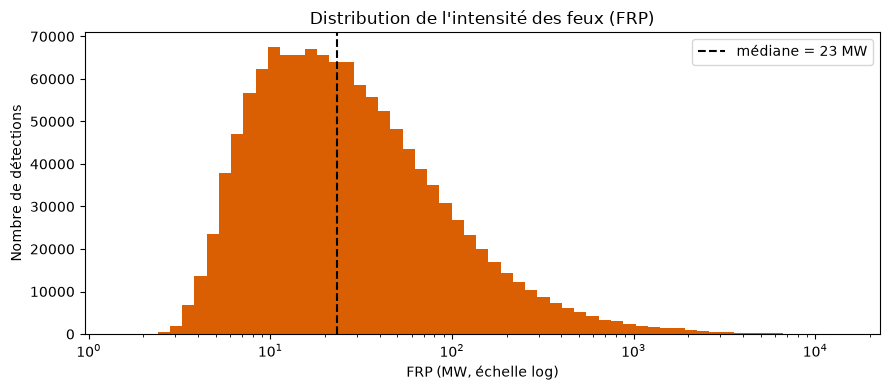

In [8]:
plot_frp_distribution(fires);

**Détections par mois** — nombre de lignes par mois, en distinguant le fichier d'archive (qualité standard) du fichier NRT (temps quasi réel).
Ce graphique montre la **saisonnalité** des feux et la **couverture temporelle** des deux fichiers.

**Ce qu'on voit :**
- **Les feux reviennent chaque année au même moment.** Le pic principal est en **août-septembre** (fin de l'été, saison sèche). Un pic secondaire apparaît au **printemps (mars-avril)**. L'hiver est calme (décembre-janvier).
- **Certaines années sont plus fortes que d'autres** : août 2015 (34 900 détections), septembre 2017 et août 2018 sortent du lot.
- **Septembre 2020 bat tous les records** avec 45 742 détections. environ 83 % sont sur la côte Ouest (Californie, Oregon, Washington — estimé avec un cadre latitude/longitude) : ce sont les grands incendies de 2020.
- **Les deux fichiers s'enchaînent bien** : l'archive s'arrête fin juin 2020 et le NRT commence le 1er juillet 2020, sans trou ni chevauchement.
- **2010 et 2020 sont des années incomplètes** (la série commence fin septembre 2010 et s'arrête fin septembre 2020). Il faudra en tenir compte pour comparer les années ou faire une prévision.

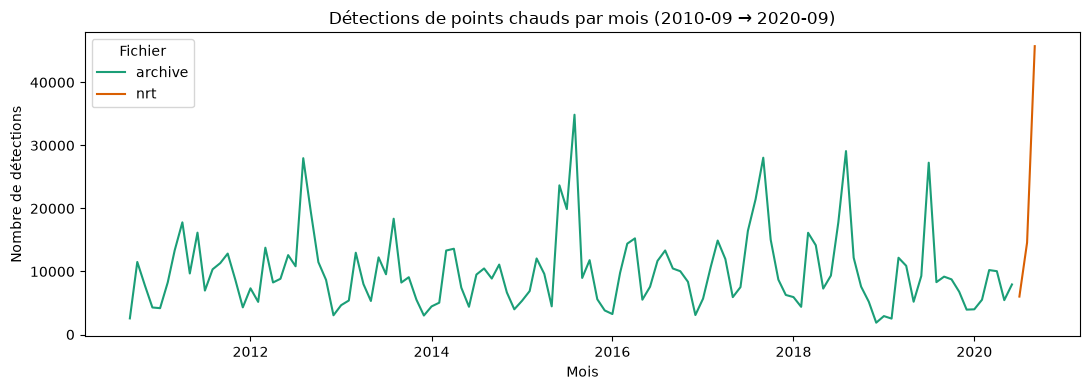

In [9]:
plot_monthly_detections(fires);

**Localisation des détections** — chaque point est une détection, colorée par `type`. Les lignes NRT n'ont pas de type (gris).

**Ce qu'on voit :**
- **Les feux de végétation (vert) sont partout**, de la côte Ouest au Sud-Est, jusqu'au centre de l'Alaska.
- **Les sources statiques (violet)** se concentrent dans l'Est et le long du golfe du Mexique : ce sont surtout des sites industriels qui chauffent en permanence (usines, raffineries).
- **Les volcans (rose)** sont à 98 % à Hawaï (volcan Kīlauea), plus quelques points dans les îles Aléoutiennes (Alaska).
- **L'offshore (bleu)** apparaît dans le golfe du Mexique : ce sont les plateformes pétrolières.
- Les points NRT (gris) sont peu visibles car ils tombent aux mêmes endroits que les feux de végétation.

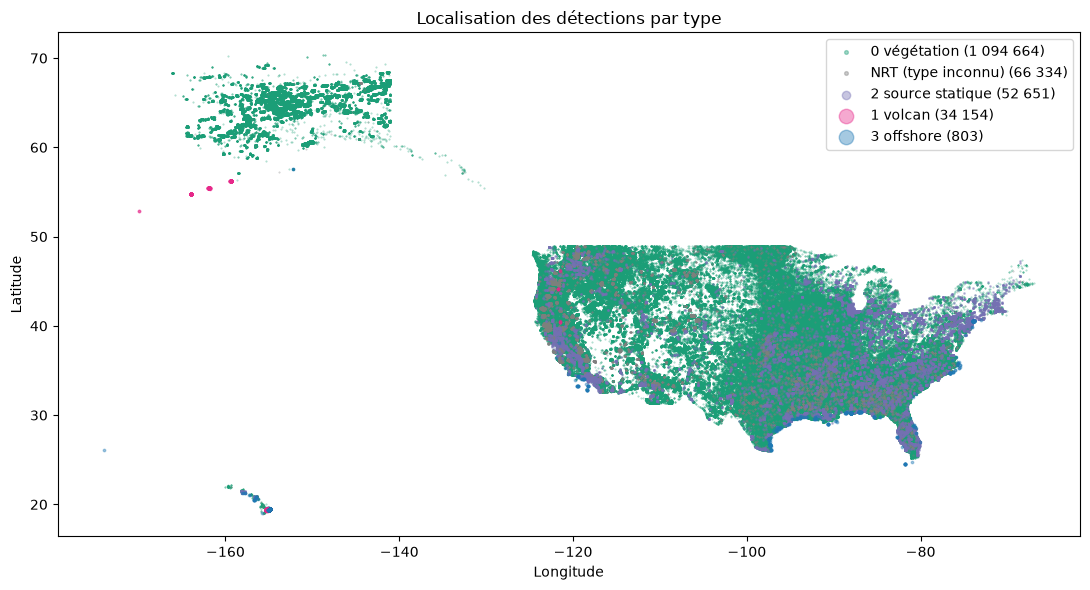

In [10]:
plot_spatial_distribution(fires);

### 1.6 Observations

**Bilan de l'exploration :**
- **1 248 606 détections**, 16 colonnes, **aucun doublon**.
- **Aucune valeur manquante**, sauf `type` pour les lignes NRT.
- **Répartition par type** : 87,7 % feux de végétation, 4,2 % sources statiques, 2,7 % volcans, moins de 0,1 % offshore, 5,3 % inconnus (NRT).
- **Confiance** : médiane à 70 %. Seulement 5,8 % des détections ont une confiance inférieure à 30 %.
- **Jour / nuit** : 79 % des détections ont lieu le jour, quand les feux sont les plus actifs.
- **Intensité (FRP)** : très inégale, avec beaucoup de petits feux et quelques très grands.

**Ce que ça implique pour la phase 2 (nettoyage) :**
1. Ne garder que les **feux de végétation** (`type = 0`) : c'est le sujet du projet. Volcans, usines et plateformes ne sont pas des incendies.
2. Décider quoi faire des **lignes NRT** sans `type` (66 334 lignes, dont le record de septembre 2020).
3. Examiner les valeurs de **FRP négatives ou nulles**.
4. Choisir un **seuil de confiance** minimum pour écarter les détections douteuses.
5. Transformer `acq_date` + `acq_time` en vraie date-heure, et ajouter des colonnes utiles (année, mois, saison).

## 2. Nettoyage & enrichissement

L'exploration (§1.6) a montré cinq points à régler. Cette section les traite un par un, puis ajoute l'**État américain** de chaque détection grâce à un second dataset.

### 2.1 Choix de nettoyage

**1. Donner un type aux lignes NRT.**
Le fichier NRT n'a pas de colonne `type`, donc on ne sait pas si une détection est un feu, un volcan ou une usine.
On utilise l'archive comme référence : les volcans, usines et plateformes ne bougent pas.
Si une détection NRT tombe dans une case d'environ 1 km × 1 km (coordonnées arrondies à 2 décimales) où l'archive a déjà vu une de ces sources, elle reçoit le même type. Sinon, on la considère comme un feu de végétation.
*Vérification :* appliquée à l'archive elle-même, cette règle ne classe à tort que 0,9 % des feux de végétation. Elle retire 1 829 lignes NRT sur 66 334.
On garde ainsi le NRT, qui contient le record de septembre 2020 et servira à tester la prévision (Q3).

**2. Ne garder que les feux de végétation (`type = 0`).** Le projet porte sur les incendies. Volcans, sites industriels et plateformes offshore chauffent en permanence et fausseraient les résultats.

**3. Retirer les FRP négatives ou nulles.** Une puissance négative est impossible. Une FRP à 0 veut dire que l'intensité n'a pas été calculée (ces lignes ont pourtant une confiance proche de 100 %). Sans intensité, la ligne est inutilisable pour nos indicateurs. Cela ne concerne que 0,1 % des lignes.

**4. Retirer les détections de faible confiance (< 30 %).** La NASA classe les détections MODIS en *faible* (< 30 %), *nominale* (30–79 %) et *haute* (≥ 80 %). Les détections faibles sont souvent de fausses alertes (reflets du soleil, sols très chauds). Elles représentent environ 5,5 % des lignes restantes.

**5. Préparer le temps.** `acq_date` + `acq_time` deviennent une vraie date-heure (`acq_datetime`, en heure UTC). On ajoute `year`, `month` et `season` (saisons de l'hémisphère Nord : hiver = décembre à février, etc.).

**6. Supprimer les colonnes devenues inutiles** (voir le tableau ci-dessous).

In [11]:
# Colonnes supprimées et raison
pd.Series(USELESS_COLUMNS, name="raison de la suppression").to_frame()

,raison de la suppression
instrument,toujours 'MODIS' : n'apporte aucune information
version,"redondant avec `source` (6.03 = archive, 6.0NR..."
type,toujours 0 après le filtre végétation
acq_time,fusionné avec acq_date dans `acq_datetime`


### 2.2 Application du nettoyage
Le tableau indique combien de lignes chaque étape retire.

In [12]:
fires_clean, cleaning_log = clean_data(fires, min_confidence=30)
cleaning_log

,étape,lignes restantes,lignes retirées
0,Données brutes (archive + NRT),1248606,0
1,Feux de végétation uniquement (type 0),1159169,89437
2,FRP > 0,1158517,652
3,Confiance >= 30 %,1094224,64293


### 2.3 Enrichissement : État et région (dataset externe)

Les données FIRMS ne donnent que des coordonnées. Pour parler d'**États** (« la Californie brûle plus que le Texas »), on utilise un second dataset :
les **limites des États américains** publiées par le *US Census Bureau* (fichier `cb_2018_us_state_20m`, dans `data/external/`).

- **Comment ?** Une *jointure spatiale* : pour chaque détection, on cherche le polygone d'État qui contient le point.
- **Cas des côtes :** les contours du Census sont simplifiés, donc quelques points côtiers tombent juste à côté. Ils sont rattachés à l'État le plus proche s'il est à moins de 10 km.
- **Région :** à partir de l'État, on ajoute la grande région officielle du Census (*Northeast, Midwest, South, West*). L'Alaska et Hawaï font partie de *West*.

In [13]:
states = load_states(config.STATES_FILE)
fires_clean = add_region(add_state(fires_clean, states))

print("Détections sans État :", fires_clean["state"].isna().sum())
fires_clean["region"].value_counts()

Détections sans État : 0


region
West         497241
South        457658
Midwest      135030
Northeast      4295
Name: count, dtype: int64

### 2.4 Résultat

On vérifie le jeu de données final (dimensions, types, valeurs manquantes), puis on le sauvegarde au format **parquet** dans `data/processed/`. Les requêtes de la section 3 partent de ce fichier, ce qui évite de refaire tout le nettoyage à chaque fois.

In [14]:
print(dataset_shape(fires_clean))
fires_clean.head()

{'rows': 1094224, 'columns': 19}


,latitude,longitude,brightness,scan,track,acq_date,satellite,confidence,bright_t31,frp,daynight,source,acq_datetime,year,month,season,state,state_name,region
0,33.1668,-95.4335,301.7,2.0,1.4,2010-09-27,Terra,44,284.6,18.9,N,archive,2010-09-27 04:57:00+00:00,2010,9,automne,TX,Texas,South
1,33.1694,-95.4404,304.2,2.0,1.4,2010-09-27,Terra,59,284.5,22.8,N,archive,2010-09-27 04:57:00+00:00,2010,9,automne,TX,Texas,South
2,38.5241,-112.5254,303.5,2.3,1.5,2010-09-27,Terra,51,285.4,24.9,N,archive,2010-09-27 04:59:00+00:00,2010,9,automne,UT,Utah,West
3,47.0787,-116.1552,303.2,2.1,1.4,2010-09-27,Terra,54,279.3,25.8,N,archive,2010-09-27 05:01:00+00:00,2010,9,automne,ID,Idaho,West
4,44.8231,-110.3774,304.7,1.3,1.1,2010-09-27,Terra,61,276.6,13.5,N,archive,2010-09-27 05:01:00+00:00,2010,9,automne,WY,Wyoming,West


In [15]:
missing_values(fires_clean).T

,latitude,longitude,brightness,scan,track,acq_date,satellite,confidence,bright_t31,frp,daynight,source,acq_datetime,year,month,season,state,state_name,region
n_missing,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
pct_missing,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [16]:
save_processed(fires_clean, config.CLEAN_FILE)
print("Sauvegardé :", config.CLEAN_FILE.relative_to(config.ROOT))

Sauvegardé : data/processed/fires_clean.parquet


**Ce qu'on retient :**
- Il reste **1 094 224 détections** de feux de végétation sur 1 248 606 (88 %).
- La plus grosse perte vient du filtre de type (89 437 lignes de volcans, usines et plateformes), puis du filtre de confiance (64 293 lignes).
- **Toutes les détections ont un État.** L'Ouest (497 k) et le Sud (458 k) concentrent presque tous les feux. Le Nord-Est n'en compte que 4 k.
- Les États les plus touchés sont la Californie (125 k), l'Alaska (78 k) et le Texas (77 k).
- Avec les États, on confirme que **81 % des détections de septembre 2020 sont en Californie, Oregon ou Washington**.

## 3. Requêtes

Quatre requêtes, chacune avec : la **question** posée, la **méthode**, les **indicateurs** (définition, calcul, lecture), le résultat et son interprétation.

| Requête | Type demandé | Méthode |
|---|---|---|
| Q1 | Agrégation | `groupby` par État, par année et par région |
| Q2 | Motifs fréquents | FP-Growth + règles d'association |
| Q3 | Temporelle | Prévision SARIMA |
| Q4 | Spatiale | Clustering DBSCAN (distance de haversine) |

Les requêtes partent du fichier nettoyé de la section 2. On peut donc reprendre ici sans relancer les sections 1 et 2.

In [17]:
fires_clean = load_processed(config.CLEAN_FILE)

### Q1 — Quels États brûlent le plus ? *(agrégation)*

**Méthode :** on regroupe les détections par État (`groupby`) et on calcule trois indicateurs.

**Indicateurs :**
| Indicateur | Calcul | Comment le lire |
|---|---|---|
| `n_detections` | Nombre de détections dans l'État | Plus il y a de pixels en feu, plus la surface brûlée et la durée des feux sont grandes. |
| `total_frp_gw` | Somme des FRP de toutes les détections ÷ 1000 (en gigawatts) | **Énergie cumulée** : mesure à la fois combien de feux il y a et à quel point ils sont violents. C'est notre indicateur principal. |
| `median_frp` | FRP médiane des détections (en MW) | Intensité d'un feu « typique » de l'État : élevée = feux violents, faible = petits feux. |
| `share_pct` | Énergie de l'État ÷ énergie totale × 100 | Part de l'État dans l'énergie de tous les feux du pays. |

On utilise la médiane et non la moyenne, car quelques feux énormes tireraient la moyenne vers le haut (voir §1.5).

In [18]:
by_state = aggregate_by_state(fires_clean)
by_state.head(10)

,state,state_name,n_detections,median_frp,total_frp_gw,share_pct
0,CA,California,124800,37.9,15637.7,19.5
1,AK,Alaska,78280,40.3,7395.1,9.2
2,ID,Idaho,57681,38.3,6545.4,8.2
3,OR,Oregon,60571,36.1,6516.5,8.1
4,WA,Washington,41772,38.5,4412.5,5.5
5,MT,Montana,36039,37.6,3898.4,4.9
6,TX,Texas,77304,17.7,3707.6,4.6
7,AZ,Arizona,29415,41.6,3076.3,3.8
8,FL,Florida,64161,19.7,2581.1,3.2
9,CO,Colorado,14146,46.9,2465.8,3.1


In [19]:
plot_state_map(by_state, metric="total_frp_gw").show()

In [20]:
plot_top_states(by_state, n=10).show()

**Complément : évolution par année et par région.** Nombre de détections par année, découpé selon les 4 grandes régions du Census (voir §2.3).

In [21]:
by_year_region = aggregate_by_year_region(fires_clean)
plot_year_region(by_year_region).show()

**Ce qu'on retient :**
- **La Californie domine** : à elle seule, 19,5 % de l'énergie de tous les feux du pays. Suivent l'Alaska, l'Idaho et l'Oregon. Les 6 premiers États sont tous à l'Ouest.
- **L'Ouest et le Sud ont des feux très différents.** L'Ouest a 45 % des détections mais **73 % de l'énergie**. Le Sud a presque autant de détections (42 %) mais seulement 21 % de l'énergie.
  Raison : la FRP médiane est de 40 MW à l'Ouest contre 17 MW au Sud. Le Sud a beaucoup de petits feux (Texas, Floride, Géorgie), l'Ouest a moins de feux mais bien plus violents.
- **Le Nord-Est ne brûle presque pas** (0,4 % des détections).
- **Les années varient beaucoup**, surtout à l'Ouest : 2015, 2017, 2018 et 2020 sont de grosses années ; 2014 et 2016 sont calmes. Le Sud reste plus stable d'une année à l'autre.

### Q2 — Quelles caractéristiques des feux vont ensemble ? *(motifs fréquents)*

**Idée :** comme pour un panier de courses (« qui achète du pain achète souvent du beurre »), on cherche les caractéristiques qui apparaissent souvent **ensemble** dans les détections.

**Méthode :**
1. Chaque détection devient une *transaction*, c'est-à-dire une liste de 4 caractéristiques :
   - **saison** (hiver, printemps, été, automne) ;
   - **région** (West, South, Midwest, Northeast) ;
   - **moment** (jour, nuit) ;
   - **intensité**, classée selon la FRP : *faible* (< 10 MW), *moyenne* (10–100 MW), *forte* (> 100 MW). Ces seuils séparent environ 20 % de petits feux et 15 % de gros feux (§1.5).
2. L'algorithme **FP-Growth** trouve les combinaisons présentes dans au moins 2 % des détections.
3. On en déduit des **règles** « si A alors B », par exemple {nuit} → West.

La *confiance de détection* n'est pas utilisée : la NASA la calcule en partie à partir de la chaleur du pixel, donc elle donnerait des règles évidentes (« feu fort → confiance haute »).
On ne garde que les règles à une seule conclusion, et on retire les règles longues qui n'apportent rien de plus que leur version courte (lift pas au moins 5 % plus élevé).

**Indicateurs (pour une règle A → B) :**
| Indicateur | Calcul | Comment le lire |
|---|---|---|
| **Support** | Part des détections qui ont A **et** B | La règle concerne-t-elle beaucoup de feux ? 0,10 = 10 % des détections. |
| **Confiance** | Parmi les détections qui ont A, part qui ont aussi B : P(B \| A) | Fiabilité de la règle. 0,9 = 9 fois sur 10, quand on voit A, on voit aussi B. |
| **Lift** | Confiance ÷ fréquence normale de B | Force du lien. **1 = aucun lien** (hasard). 2 = B est deux fois plus fréquent quand A est présent. |

Seuils retenus : support ≥ 2 %, confiance ≥ 50 %, lift ≥ 1,2.

In [22]:
transactions = build_transactions(fires_clean)
rules = mine_rules(transactions, min_support=0.02, min_confidence=0.5, min_lift=1.2)
print(len(rules), "règles")
rules

19 règles


,antecedents,consequents,support,confidence,lift
0,région=Midwest,saison=printemps,0.078,0.634,2.441
1,"intensité=forte, moment=nuit",région=West,0.027,0.931,2.049
2,"moment=nuit, saison=été",région=West,0.105,0.922,2.029
3,"intensité=forte, saison=été",région=West,0.071,0.912,2.008
4,"moment=nuit, région=West",saison=été,0.105,0.679,2.000
5,saison=hiver,région=South,0.097,0.824,1.970
6,"intensité=forte, région=West",saison=été,0.071,0.657,1.935
7,moment=nuit,région=West,0.155,0.870,1.915
8,moment=nuit,saison=été,0.114,0.641,1.888
9,région=West,saison=été,0.268,0.590,1.738


In [23]:
plot_rules(rules, top=15).show()

**Ce qu'on retient :** les règles décrivent trois « profils » de feux.
- **Le feu de l'Ouest : l'été, fort, et qui brûle la nuit.**
  - {nuit, été} → West : 92 % des feux d'été détectés la nuit sont à l'Ouest (lift 2,0).
  - {forte intensité, nuit} → West : 93 % (lift 2,0).

  Un feu encore visible la nuit est un grand incendie qui ne s'éteint pas : c'est typique des feux de forêt de l'Ouest.
- **Le feu du Sud : l'hiver, faible, et de jour.**
  - {hiver} → South : 82 % des feux d'hiver sont dans le Sud (lift 2,0).
  - {faible intensité, jour} → South (lift 1,6).

  Ce sont probablement des brûlages contrôlés (agriculture, entretien des forêts), faits de jour et hors saison sèche.
- **Le feu du Midwest : le printemps.**
  - {Midwest} → printemps : 63 % des feux du Midwest ont lieu au printemps (lift 2,4, la règle la plus forte).

  Cela correspond au brûlage des prairies et des champs avant les cultures (Kansas, Nebraska…).

Ces règles rejoignent Q1 : l'Ouest concentre les feux violents, le Sud les petits feux nombreux.

### Q3 — Combien de feux le mois prochain ? *(prévision temporelle)*

**Question :** peut-on prévoir le nombre de détections de chaque mois à partir des années passées ?

**Méthode :**
1. On compte les détections par mois (oct. 2010 → sept. 2020). Septembre 2010 est retiré, car il ne contient que 4 jours de données.
2. On garde les **12 derniers mois** (oct. 2019 → sept. 2020) pour le **test**. Le modèle apprend sur les 9 années précédentes, puis on compare sa prévision à la réalité.
3. Modèle **SARIMA** (*Seasonal ARIMA*) : il prédit chaque mois à partir des mois précédents **et** du même mois des années précédentes, ce qui permet de capter le cycle annuel des feux (§1.5).
   - Réglages : SARIMA(1,0,1)(1,1,1)₁₂, où 12 correspond à une saison de 12 mois.
   - Le modèle travaille sur le **logarithme** des comptages, pour que les énormes pics d'été ne déséquilibrent pas l'apprentissage. Cela garantit aussi des prévisions positives.
4. On compare SARIMA à une **méthode naïve** : « ce mois-ci, il y aura autant de feux que le même mois l'an dernier ». Un modèle utile doit faire mieux que ça.
5. Enfin, on réentraîne le modèle sur toute la série et on prévoit les **12 mois suivants** (oct. 2020 → sept. 2021).

**Indicateurs :**
| Indicateur | Calcul | Comment le lire |
|---|---|---|
| **Prévision** | Valeur prédite par SARIMA pour chaque mois | Nombre de détections attendu. |
| **Intervalle à 80 %** | Bande colorée autour de la prévision | Le vrai chiffre a 80 % de chances d'être dedans. Plus elle est large, plus le modèle est incertain. |
| **MAPE** | Moyenne, sur les mois de test, de \|réel − prévu\| ÷ réel × 100 | Erreur moyenne en %. 30 % = la prévision se trompe en moyenne de 30 %. Plus c'est bas, mieux c'est. |

In [24]:
series = monthly_series(fires_clean)
train, test = split_train_test(series, test_start="2019-10-01")
print(f"Apprentissage : {len(train)} mois — Test : {len(test)} mois")

model = fit_sarima(train)
test_pred = forecast(model, steps=len(test))
comparison, mape = evaluate_forecast(series, test, test_pred)
comparison

Apprentissage : 108 mois — Test : 12 mois


,réel,SARIMA,naïf (N-1)
2019-10-01,7878,8951,6836
2019-11-01,6248,5926,4496
2019-12-01,3604,3068,1673
2020-01-01,3610,3908,2657
2020-02-01,5004,5123,2326
2020-03-01,9529,12877,11340
2020-04-01,9291,11055,10071
2020-05-01,4753,5005,4510
2020-06-01,6931,7442,8071
2020-07-01,4850,12858,23785


In [25]:
mape

SARIMA        31.2
naïf (N-1)    61.9
Name: MAPE (%), dtype: float64

In [26]:
# Prévision des 12 mois suivants, avec le modèle réentraîné sur toute la série
future_pred = forecast(fit_sarima(series), steps=12)
plot_forecast(series, test_pred, future_pred, test_start="2019-10-01").show()

**Ce qu'on retient :**
- **SARIMA fait deux fois mieux que la méthode naïve** : 31 % d'erreur moyenne contre 62 %. Le modèle a bien appris le cycle annuel (creux en hiver, pics au printemps et en fin d'été).
- **Mais il rate complètement septembre 2020** : il prévoyait environ 11 000 détections, il y en a eu 42 000 (presque 4 fois plus). C'est la limite d'un modèle basé sur le passé : il ne peut pas prévoir un événement **exceptionnel**. Les incendies de 2020 sur la côte Ouest ont dépassé tout ce qui avait été observé en 10 ans.
- **La prévision future** reprend le cycle habituel, avec un pic attendu en août 2021 autour de 14 000 détections, mais une bande d'incertitude large (8 000 à 24 000).
- Pour faire mieux, il faudrait ajouter des données météo (sécheresse, température, vent), qui expliquent les années extrêmes.

### Q4 — Où sont les grands foyers d'incendie ? *(clustering spatial)*

**Question :** pendant la saison record d'**août-septembre 2020**, où se trouvaient les grands incendies et lesquels ont été les plus violents ?

**Méthode :**
1. On garde les détections d'août-septembre 2020 avec une **confiance haute (≥ 80 %)**, pour ne travailler que sur des points sûrs. Cela donne 34 395 points.
   On se limite à deux mois car DBSCAN ne regarde que la position : sur une année entière, il fusionnerait des feux différents survenus au même endroit à des mois d'écart.
2. **DBSCAN** regroupe les points proches :
   - un **foyer** est un groupe d'au moins 20 détections, chacune à moins de 5 km d'une autre ;
   - les points isolés sont classés comme « bruit » ;
   - on n'a pas besoin de fixer le nombre de foyers à l'avance, et les foyers peuvent avoir n'importe quelle forme. C'est adapté à des incendies.
3. La distance utilisée est celle de **haversine** : la vraie distance à la surface de la Terre, qui est ronde. Une distance « à plat » sur latitude/longitude serait fausse.

**Indicateurs (par foyer) :**
| Indicateur | Calcul | Comment le lire |
|---|---|---|
| `n_detections` | Nombre de détections du foyer | Taille du foyer (surface × durée). |
| `total_frp_gw` | Somme des FRP ÷ 1000 (GW) | **Énergie totale** du foyer : sert à classer les foyers (rang 1 = le plus violent). |
| `start`, `end`, `duration_days` | Première et dernière date de détection, et écart en jours | Quand le feu a commencé, et combien de temps il a duré. |
| `latitude`, `longitude` | Moyenne des positions | Centre du foyer. |
| `state` | État le plus présent dans le foyer | Où se trouve le foyer. |
| % de bruit | Points hors foyer ÷ total | Part des petits feux isolés. |

In [27]:
points = select_points(fires_clean, start="2020-08-01", end="2020-09-30", min_confidence=80)
clustered = spatial_clustering(points, eps_km=5, min_samples=20)
clusters = summarize_clusters(clustered)

print(f"{len(points)} détections → {len(clusters)} foyers ; "
      f"bruit : {(clustered['cluster'] < 0).mean():.1%}")
clusters.head(10)

34395 détections → 77 foyers ; bruit : 7.1%


,rank,cluster,n_detections,total_frp_gw,start,end,latitude,longitude,state,duration_days
0,1,14,6039,1524.0,2020-08-17,2020-09-27,39.90,-122.96,CA,42
1,2,16,2942,761.9,2020-08-17,2020-09-20,44.84,-122.03,OR,35
2,3,44,3010,758.2,2020-09-05,2020-09-27,37.30,-119.31,CA,23
3,4,17,1752,622.8,2020-08-18,2020-09-27,39.74,-121.16,CA,41
4,5,9,733,399.9,2020-08-14,2020-09-26,40.64,-105.73,CO,44
5,6,30,1507,385.9,2020-08-21,2020-09-27,36.19,-118.53,CA,38
6,7,65,706,317.8,2020-09-08,2020-09-23,41.95,-123.50,CA,16
7,8,60,1224,302.5,2020-09-08,2020-09-18,44.14,-122.47,OR,11
8,9,63,728,263.9,2020-09-08,2020-09-17,43.36,-122.92,OR,10
9,10,12,1037,246.1,2020-08-16,2020-09-25,34.31,-117.94,CA,41


In [28]:
plot_clusters(clustered, clusters, top=10).show()

**Ce qu'on retient :**
- DBSCAN trouve **77 foyers**. Seulement 7 % des points sont isolés : en 2020, presque toutes les détections sûres appartiennent à de grands incendies.
- **Les 10 foyers les plus violents sont tous à l'Ouest** : 6 en Californie, 3 en Oregon et 1 au Colorado.
- **Le foyer n°1**, au nord de la Californie, regroupe 6 000 détections et 1 524 GW, soit deux fois plus que le n°2. Il a duré 42 jours (17 août → fin septembre).
- Les dates et positions correspondent aux grands incendies connus de 2020 (à vérifier sur les sites officiels CAL FIRE / InciWeb) :
  - n°1 : *August Complex* (CA), le plus grand incendie de l'histoire de la Californie ;
  - n°2 : *Beachie Creek / Lionshead* (OR) ;
  - n°3 : *Creek Fire* (CA, à partir du 5 septembre) ;
  - n°4 : *North Complex* (CA) ;
  - n°5 : *Cameron Peak* (CO).
- Beaucoup de foyers démarrent **entre le 16 et le 18 août** : une série d'orages secs a allumé de nombreux feux en même temps. D'autres démarrent **autour du 8 septembre**, lors d'un épisode de vents violents en Oregon.

On voit qu'un simple clustering sur des points satellites suffit à retrouver les grands incendies d'une saison, sans aucune information au sol.

## 4. Dashboard

Le dashboard (**Python Dash**) rassemble les résultats des 4 requêtes sur une seule page :
- **en-tête** : nom du projet, nom du dataset (et du dataset externe), membres de l'équipe, lien GitHub ;
- **chiffres clés** : nombre de détections analysées, période, État le plus touché, mois record ;
- **une section par requête**, avec la question posée, la lecture des indicateurs et des contrôles interactifs :

| Section | Contrôle | Effet |
|---|---|---|
| Q1 | Liste déroulante | Change l'indicateur de la carte : énergie cumulée, nombre de détections ou FRP médiane. |
| Q2 | Curseur | Change le nombre de règles affichées. |
| Q3 | — | Prévision, erreurs (MAPE) et tableau réel / prévu. |
| Q4 | Curseur « rayon » (3 à 10 km) | **Relance DBSCAN en direct** et met à jour la carte et le tableau des foyers. |

**Lancement :** le dashboard est lancé à la fin du notebook, par le bloc `main`. On peut aussi le lancer hors du notebook avec `python scripts/run_dashboard.py`, puis ouvrir http://127.0.0.1:8050.

**Preuve de fonctionnement** (exigée par les consignes), dans `reports/` :
- `Maigre_dashboard.html` : version statique du dashboard, qui s'ouvre dans n'importe quel navigateur, sans Python ni internet ;
- `Maigre_dashboard.pdf` : impression du dashboard en fonctionnement ;
- `figures/dashboard_screenshot.png` : capture d'écran complète.

La cellule ci-dessous calcule les résultats et régénère l'export HTML.

In [ ]:
results = compute_results(fires_clean)
export_dashboard_html(results, config.DASHBOARD_HTML)
print("Export :", config.DASHBOARD_HTML.relative_to(config.ROOT))

## Main block

In [29]:
if __name__ == "__main__":
    # Step 1: Data collection
    archive = load_data(config.ARCHIVE_FILE)
    nrt = load_data(config.NRT_FILE)
    fires = merge_archive_nrt(archive, nrt)
    print(dataset_shape(fires))

    # Step 2: Cleaning & enrichment
    fires_clean, cleaning_log = clean_data(fires, min_confidence=30)
    fires_clean = add_region(add_state(fires_clean, load_states(config.STATES_FILE)))
    save_processed(fires_clean, config.CLEAN_FILE)
    print(cleaning_log)

    # Step 3: Indicators construction — les 4 requêtes
    # (compute_results appelle aggregate_by_state, mine_rules, fit_sarima, spatial_clustering…)
    results = compute_results(fires_clean)
    print("Q1 — État le plus touché :", results["by_state"].iloc[0]["state_name"])
    print("Q2 —", len(results["rules"]), "règles d'association")
    print("Q3 — MAPE :", results["mape"].to_dict())
    print("Q4 —", len(results["clusters"]), "foyers d'incendie")

    # Step 4: Dashboard — export HTML (preuve) puis lancement du prototype
    export_dashboard_html(results, config.DASHBOARD_HTML)
    app = build_app(results)
    port = free_port(8050)  # 8050, ou le suivant s'il est déjà pris
    app.run(jupyter_mode="inline", port=port)  # affiché sous la cellule ; ou http://127.0.0.1:<port>


{'rows': 1248606, 'columns': 16}
                                    étape  lignes restantes  lignes retirées
0          Données brutes (archive + NRT)           1248606                0
1  Feux de végétation uniquement (type 0)           1159169            89437
2                                 FRP > 0           1158517              652
3                       Confiance >= 30 %           1094224            64293
SARIMA        31.2
naïf (N-1)    61.9
Name: MAPE (%), dtype: float64
